<a href="https://colab.research.google.com/github/vyshnavichalla7-del/id_project/blob/main/Id_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Model Coefficient: 8.589973614775724
Model Intercept: 8.195778364116101
Mean Absolute Error: 1.7346965699208434
R2 Score: 0.9940259513883952

Enter study hours: 5
Predicted Marks: 51.15


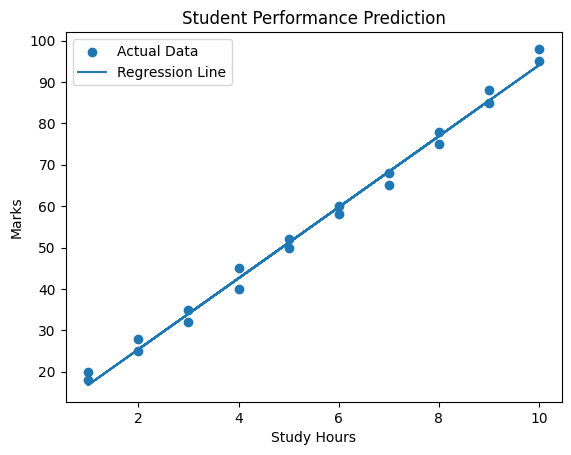

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Create sample dataset
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
                    2, 4, 6, 8, 3, 5, 7, 9, 1, 10],
    "Marks": [20, 25, 35, 40, 50, 60, 65, 75, 85, 95,
              28, 45, 58, 78, 32, 52, 68, 88, 18, 98]
}

df = pd.DataFrame(data)

# Input and output
X = df[["Study_Hours"]]
y = df["Marks"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict test marks
y_pred = model.predict(X_test)

print("Model Coefficient:", model.coef_[0])
print("Model Intercept:", model.intercept_)
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))
# Predict marks for new study hours
hours = float(input("\nEnter study hours: "))
predicted_marks = model.predict(pd.DataFrame({
"Study_Hours": [hours]
}))
print("Predicted Marks:", round(predicted_marks[0], 2))
# Visualize data and regression line
plt.scatter(df["Study_Hours"], df["Marks"], label="Actual Data")
plt.plot(
df["Study_Hours"],
model.predict(X),
label="Regression Line"
)
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Student Performance Prediction")
plt.legend()
plt.show()

First Five Rows:
   Time_on_App  Yearly_Amount_Spent
0          5.2                  450
1          6.1                  520
2          4.8                  410
3          7.5                  610
4          8.2                  680

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Time_on_App          30 non-null     float64
 1   Yearly_Amount_Spent  30 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 612.0 bytes

Mean Absolute Error: 7.37880492462359
R2 Score: 0.9876126183064173

Enter time spent on app: 5
Predicted Yearly Amount Spent: 430.14


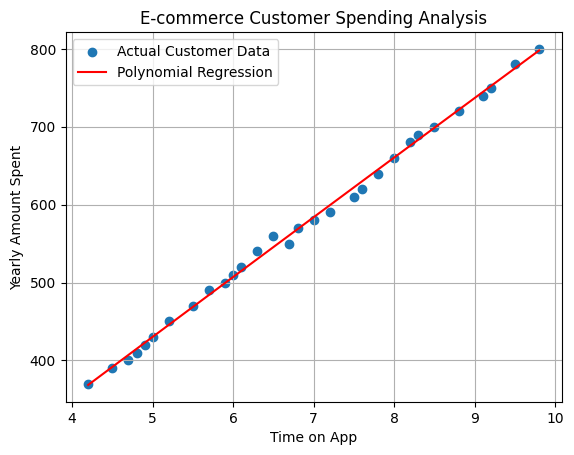

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, r2_score


# 1. Create sample e-commerce customer dataset
# This sample dataset allows the program to run
# without requiring an external CSV file.

data = {
    "Time_on_App": [
        5.2, 6.1, 4.8, 7.5, 8.2,
        5.9, 6.8, 9.1, 4.5, 7.2,
        8.5, 5.5, 6.3, 9.5, 4.9,
        7.8, 8.8, 6.5, 5.7, 9.2,
        4.2, 7.0, 8.0, 6.0, 5.0,
        9.8, 7.6, 6.7, 8.3, 4.7
    ],

    "Yearly_Amount_Spent": [
        450, 520, 410, 610, 680,
        500, 570, 740, 390, 590,
        700, 470, 540, 780, 420,
        640, 720, 560, 490, 750,
        370, 580, 660, 510, 430,
        800, 620, 550, 690, 400
    ]
}

df = pd.DataFrame(data)

# 2. Display dataset information
print("First Five Rows:")
print(df.head())

print("\nDataset Information:")
df.info()

# 3. Separate input and output

X = df[["Time_on_App"]]
y = df["Yearly_Amount_Spent"]

# 4. Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# 5. Create polynomial regression model

model = make_pipeline(
    PolynomialFeatures(
        degree=2,
        include_bias=False
    ),
    LinearRegression()
)

# 6. Train model

model.fit(X_train, y_train)

# 7. Predict tests

y_pred = model.predict(X_test)

# 8. Evaluate model

print("\nMean Absolute Error:",
      mean_absolute_error(y_test, y_pred))

print("R2 Score:",
      r2_score(y_test, y_pred))
# 9. Predict customer spending

time = float(input("\nEnter time spent on app: "))

prediction = model.predict(
    pd.DataFrame({
        "Time_on_App": [time]
    })
)

print(
    "Predicted Yearly Amount Spent:",
    round(prediction[0], 2)
)


# 10. Visualize data and regression curve


X_plot = pd.DataFrame({
    "Time_on_App": sorted(df["Time_on_App"])
})

y_plot = model.predict(X_plot)

plt.scatter(
    df["Time_on_App"],
    df["Yearly_Amount_Spent"],
    label="Actual Customer Data"
)

plt.plot(
    X_plot["Time_on_App"],
    y_plot,
    color="red",
    label="Polynomial Regression"
)

plt.xlabel("Time on App")
plt.ylabel("Yearly Amount Spent")
plt.title("E-commerce Customer Spending Analysis")
plt.legend()
plt.grid(True)
plt.show()

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
# Load dataset
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
data = pd.read_csv(url, sep="\t", header=None,
names=["label", "message"])
# Convert labels
data["label"] = data["label"].map({
"ham": 0,
"spam": 1
})
data = data.dropna()
# Separate input and output
X = data["message"]
y = data["label"]
# Convert text into numerical features
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(X)
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42, stratify=y
)
# Train model
model = MultinomialNB()
model.fit(X_train, y_train)
# Evaluate model
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))
# Test a new message
message = input("\nEnter a message: ")
message_vector = vectorizer.transform([message])
prediction = model.predict(message_vector)

if prediction[0] == 1:
    print("Result: SPAM MESSAGE")
else:
    print("Result: NOT SPAM")

Accuracy: 0.9829596412556054

Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       966
           1       0.93      0.95      0.94       149

    accuracy                           0.98      1115
   macro avg       0.96      0.97      0.96      1115
weighted avg       0.98      0.98      0.98      1115


Enter a message: hey,how are you? are u coming college today?
Result: NOT SPAM
